# Flight Price Prediction

**Business question:** what drives the price of a domestic flight ticket, and can we predict it well enough to
guide travellers ("book now or wait?") and pricing teams?

This notebook rebuilds the Final Project of the Digital Skola Data Science Bootcamp (team Yggdrasil / Kel 2), where
I worked on data cleaning, EDA, feature engineering, modelling, evaluation and the presentation.

**Data:** Airlines Flights Data (public), 300,153 one-way flights between six major Indian cities, booked
1–49 days before departure (`data/airlines_flights_data.csv.gz`). Prices are in Indian rupees (INR).

In [1]:
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Load and check the data

In [2]:
raw = pd.read_csv("data/airlines_flights_data.csv.gz")
print(raw.shape, "| missing values:", raw.isna().sum().sum(), "| duplicate rows:", raw.duplicated().sum())
raw.head()

(300153, 12) | missing values: 0 | duplicate rows: 0


,index,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


## 2. Clean and engineer features

* Drop `index` (row number) and `flight` (1,561 flight codes, too specific to generalise and impractical for users to enter).
* Add `route` = source city + destination city, because price depends on the city pair, not on each city alone.
* Remove rows that become exact duplicates after dropping those columns.

In [3]:
df = raw.drop(columns=["index", "flight"])
df["route"] = df["source_city"] + " - " + df["destination_city"]
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {before - len(df):,} duplicates -> {len(df):,} rows")
cat_cols = ["airline", "source_city", "departure_time", "stops", "arrival_time",
            "destination_city", "class", "route"]
num_cols = ["duration", "days_left"]
df[cat_cols].nunique()

Removed 2,213 duplicates -> 297,940 rows


,0
airline,6
source_city,6
departure_time,6
stops,3
arrival_time,6
destination_city,6
class,2
route,30


## 3. What drives the price?

           count   median     mean
class                             
Business   93173  53164.0  52591.0
Economy   204767   5780.0   6591.0


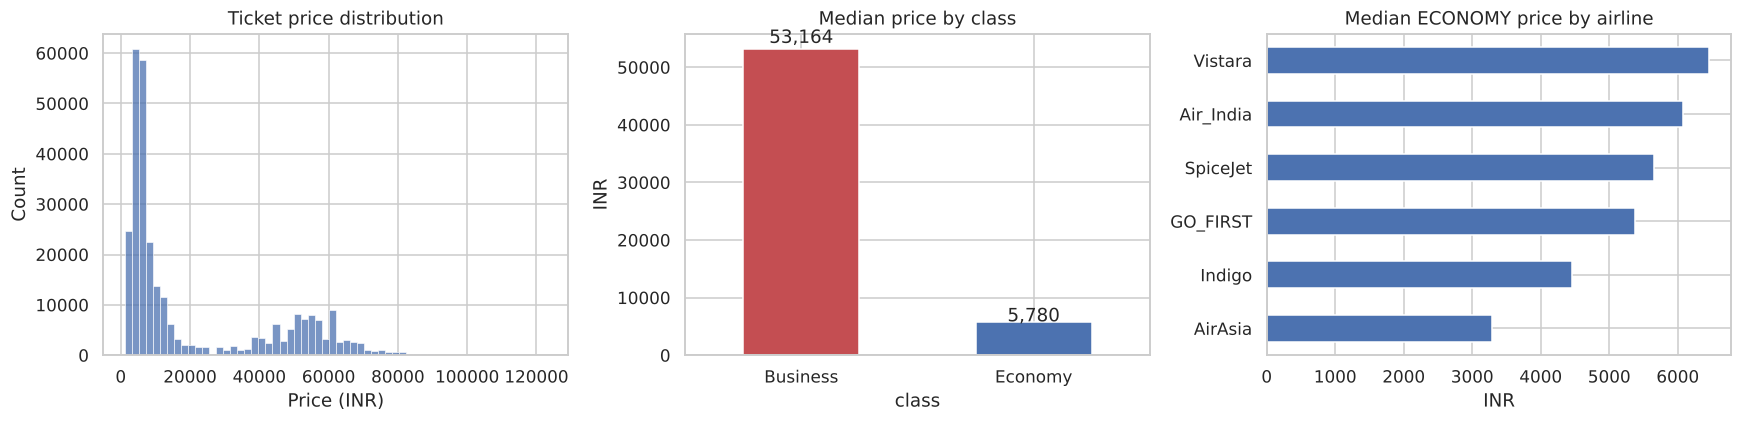

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["price"], bins=60, ax=axes[0], color="#4C72B0")
axes[0].set(title="Ticket price distribution", xlabel="Price (INR)")
cls = df.groupby("class")["price"].median()
cls.plot(kind="bar", ax=axes[1], color=["#C44E52", "#4C72B0"], rot=0)
axes[1].set(title="Median price by class", ylabel="INR")
for i, v in enumerate(cls.values):
    axes[1].text(i, v * 1.02, f"{v:,.0f}", ha="center")
air = df[df["class"] == "Economy"].groupby("airline")["price"].median().sort_values()
air.plot(kind="barh", ax=axes[2], color="#4C72B0")
axes[2].set(title="Median ECONOMY price by airline", xlabel="INR", ylabel="")
plt.tight_layout()
print((df.groupby("class")["price"].agg(["count", "median", "mean"])).round(0).to_string())

Prices form two separate markets. **the median Business ticket costs about 9 times the median Economy ticket**, so `class` will
dominate any model. Within Economy, airlines still differ clearly, with Vistara and Air India priced above the low-cost carriers.

Economy median price by booking window (INR):
days_left
1-2 days      13673.0
3-7 days      11007.0
8-14 days     10018.0
15-21 days     5507.0
22-49 days     4819.0

Booking 22-49 days ahead vs 1-2 days ahead: 65% cheaper


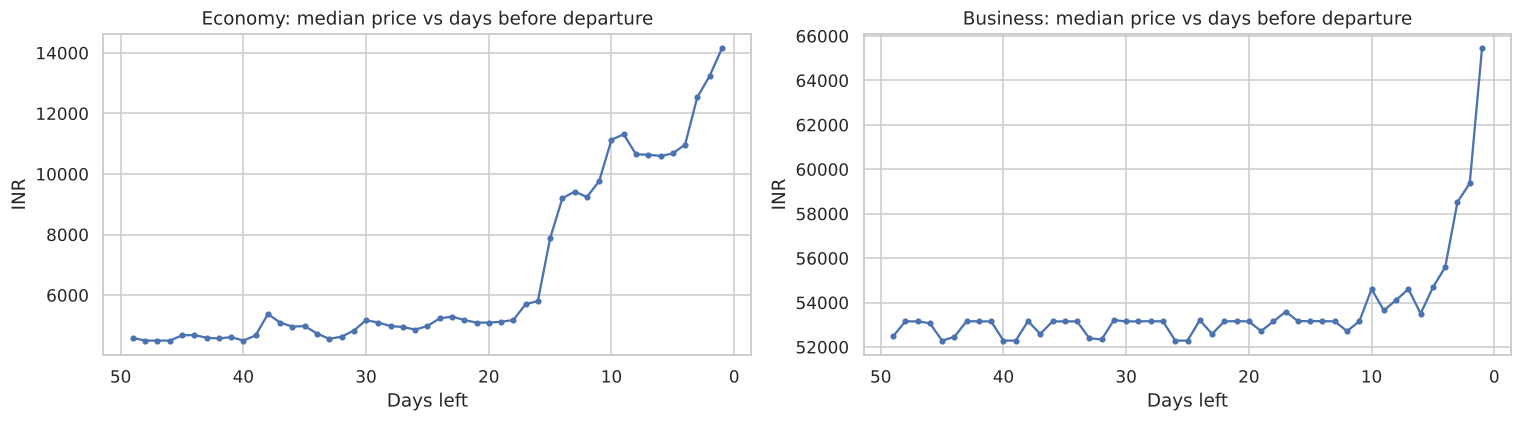

In [5]:
booking = (df.groupby(["class", "days_left"])["price"].median().reset_index())
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, c in zip(axes, ["Economy", "Business"]):
    sub = booking[booking["class"] == c]
    ax.plot(sub["days_left"], sub["price"], marker=".", color="#4C72B0")
    ax.set(title=f"{c}: median price vs days before departure", xlabel="Days left", ylabel="INR")
    ax.invert_xaxis()
plt.tight_layout()

eco = df[df["class"] == "Economy"]
win = eco.groupby(pd.cut(eco["days_left"], [0, 2, 7, 14, 21, 49],
                         labels=["1-2 days", "3-7 days", "8-14 days", "15-21 days", "22-49 days"]),
                  observed=True)["price"].median()
print("Economy median price by booking window (INR):")
print(win.round(0).to_string())
print(f"\nBooking 22-49 days ahead vs 1-2 days ahead: {1 - win.iloc[-1] / win.iloc[0]:.0%} cheaper")

In [6]:
stops = df.groupby(["class", "stops"])["price"].median().unstack(0).round(0)
print("Median price by number of stops (INR):")
print(stops.to_string())
print("\nCorrelation with price:")
print(df[["duration", "days_left", "price"]].corr()["price"].round(2).to_string())

Median price by number of stops (INR):
class        Business  Economy
stops                         
one           54608.0   5937.0
two_or_more   68743.0   8012.0
zero          27792.0   3453.0

Correlation with price:
duration     0.20
days_left   -0.09
price        1.00


**Findings**

1. **Booking window matters most for Economy travellers.** Prices climb sharply in the last two weeks before departure, and the last few days are by far the most expensive.
2. **Stops are not a discount.** One-stop flights are typically priced *above* non-stop flights, because they serve longer routes and different airlines.
3. **Duration has only a weak linear link to price (r = 0.20)**, so a non-linear model is needed to combine class, airline, route and timing.

## 4. Model comparison

The data is split 80/20 into train and test sets. Four models are compared:

* **Ridge regression**: linear baseline with one-hot encoding.
* **Decision tree**: simple non-linear model.
* **Random forest**: an ensemble of trees. It is trained on a 60,000-row sample to keep the training time short.
* **Histogram gradient boosting**: scikit-learn's fast boosting model, which handles the categorical features natively.

The metrics are MAE and RMSE in rupees, R², and MAPE (average percentage error).

In [7]:
X = df.drop(columns="price")
y = df["price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

onehot = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
                            ("num", StandardScaler(), num_cols)])
ordinal = ColumnTransformer([("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat_cols),
                             ("num", "passthrough", num_cols)])

candidates = {
    "Ridge (baseline)": Pipeline([("prep", onehot), ("model", Ridge(alpha=1.0))]),
    "Decision Tree": Pipeline([("prep", ordinal), ("model", DecisionTreeRegressor(min_samples_leaf=5, random_state=RANDOM_STATE))]),
    "Random Forest (60k sample)": Pipeline([("prep", ordinal), ("model", RandomForestRegressor(
        n_estimators=150, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE))]),
    "Hist Gradient Boosting": Pipeline([("prep", ordinal), ("model", HistGradientBoostingRegressor(
        categorical_features=list(range(len(cat_cols))), max_iter=500, learning_rate=0.1,
        max_leaf_nodes=63, random_state=RANDOM_STATE))]),
}

def score(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred),
            "MAPE_%": np.mean(np.abs(y_true - y_pred) / y_true) * 100}

rows, fitted = [], {}
sample_idx = X_train.sample(60000, random_state=RANDOM_STATE).index
for name, pipe in candidates.items():
    t0 = time.time()
    Xt, yt = (X_train.loc[sample_idx], y_train.loc[sample_idx]) if "sample" in name else (X_train, y_train)
    pipe.fit(Xt, yt)
    fitted[name] = pipe
    rows.append({"model": name, **score(y_test, pipe.predict(X_test)),
                 "train_R2": r2_score(yt, pipe.predict(Xt)), "train_seconds": time.time() - t0})
results = pd.DataFrame(rows).set_index("model").sort_values("RMSE")
results.round({"MAE": 0, "RMSE": 0, "R2": 3, "MAPE_%": 1, "train_R2": 3, "train_seconds": 1})

,MAE,RMSE,R2,MAPE_%,train_R2,train_seconds
model,,,,,,
Hist Gradient Boosting,1493.0,2760.0,0.985,11.8,0.987,8.8
Decision Tree,1194.0,2918.0,0.983,8.2,0.991,1.1
Random Forest (60k sample),1436.0,3020.0,0.982,10.2,0.994,11.2
Ridge (baseline),4576.0,6734.0,0.912,47.3,0.913,0.8


**Histogram gradient boosting** has the lowest RMSE, the highest R² and the smallest train-test gap (0.987 vs 0.985), so it is the final model.
The decision tree has a lower MAE and MAPE, so it is very accurate on typical cheap tickets, but its RMSE is higher. That means it makes
more large misses, and its train-test gap is wider. For a pricing tool, avoiding large misses on expensive tickets matters more.

## 5. Final model: where is it accurate, where not?

             MAE    RMSE     R2  MAPE_%
class                                  
Business  2692.0  4353.0  0.888     5.0
Economy    950.0  1577.0  0.820    14.9


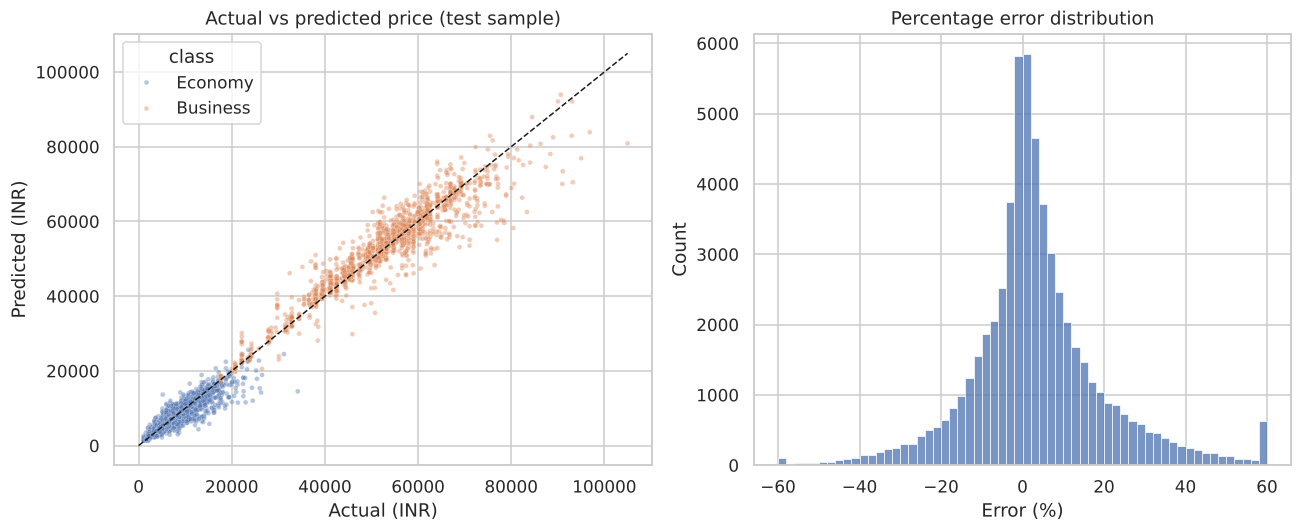

In [8]:
best = fitted["Hist Gradient Boosting"]
pred = best.predict(X_test)
eval_df = X_test.assign(actual=y_test.values, pred=pred)
by_class = eval_df.groupby("class").apply(lambda g: pd.Series(score(g["actual"], g["pred"])), include_groups=False)
print(by_class.round({"MAE": 0, "RMSE": 0, "R2": 3, "MAPE_%": 1}).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
s = eval_df.sample(6000, random_state=RANDOM_STATE)
sns.scatterplot(data=s, x="actual", y="pred", hue="class", s=10, alpha=0.4, ax=axes[0])
lim = [0, s[["actual", "pred"]].max().max()]
axes[0].plot(lim, lim, "k--", lw=1)
axes[0].set(title="Actual vs predicted price (test sample)", xlabel="Actual (INR)", ylabel="Predicted (INR)")
err = (eval_df["pred"] - eval_df["actual"]) / eval_df["actual"] * 100
sns.histplot(err.clip(-60, 60), bins=60, ax=axes[1], color="#4C72B0")
axes[1].set(title="Percentage error distribution", xlabel="Error (%)")
plt.tight_layout()

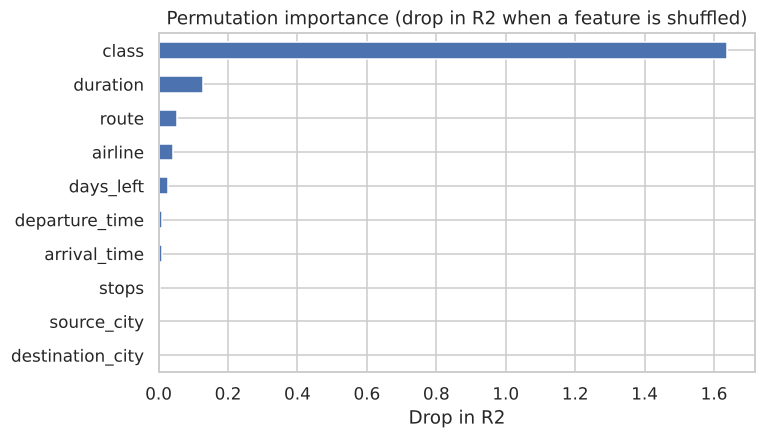

,0
class,1.637
duration,0.127
route,0.052
airline,0.042
days_left,0.028
departure_time,0.009
arrival_time,0.009
stops,0.003
source_city,0.001
destination_city,0.001


In [9]:
from sklearn.inspection import permutation_importance
sample = X_test.sample(5000, random_state=RANDOM_STATE)
imp = permutation_importance(best, sample, y_test.loc[sample.index], n_repeats=3,
                             random_state=RANDOM_STATE, scoring="r2")
importance = pd.Series(imp.importances_mean, index=sample.columns).sort_values()
ax = importance.plot(kind="barh", figsize=(7, 4), color="#4C72B0")
ax.set(title="Permutation importance (drop in R2 when a feature is shuffled)", xlabel="Drop in R2")
importance.sort_values(ascending=False).round(3)

## 6. Save the model for the Streamlit app

In [10]:
joblib.dump(best, "app/flight_price_model.joblib", compress=3)
options = {c: sorted(df[c].unique().tolist()) for c in ["airline", "source_city", "destination_city",
                                                        "departure_time", "arrival_time", "stops", "class"]}
route_duration = df.groupby(["source_city", "destination_city", "stops"])["duration"].median().round(2)
joblib.dump({"options": options, "route_duration": route_duration}, "app/app_metadata.joblib", compress=3)
final_scores = results.loc["Hist Gradient Boosting"]
print(f"Saved. Test R2 {final_scores['R2']:.3f}, MAE {final_scores['MAE']:,.0f} INR, MAPE {final_scores['MAPE_%']:.1f}%")

Saved. Test R2 0.985, MAE 1,493 INR, MAPE 11.8%


## 7. Conclusions and recommendations

* **For travellers:** book Economy at least two to three weeks ahead. Last-minute fares are much higher.
* **For pricing and revenue teams:** class, route, airline and booking window explain almost all of the price variation, and the model predicts prices with about 12% average error. It can be used to flag fares that look too high or too low for their route and timing.
* **Limitations:** the data covers one season and six cities in India. Business fares have a much higher absolute error in rupees (but a lower percentage error). Retrain on newer data before any production use.